# 13 · Turn traces into regressions

Can an evaluation detect a real defect without confusing it with a judge disagreement?

Emit correlated request, retrieval and tool spans without raw sensitive fields. Compare deterministic graders and calibrated human labels on known-good and known-bad fixtures. Add discovered categories to development data and rerun a fixed gate.

**Measures** — Grader agreement, false passes, paired change by slice and trace coverage.

**Evidence** — Versioned evaluation manifest, trace bundle and regression report.

**Runtime** — CPU replay, T4 for model pairs. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1', 'sentencepiece': '0.2.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}  # pragma: allowlist secret
LAB_NUMBER = 13

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


### Which spans let us turn a failure into a test?

The on-call reviewer sees a valid JSON reply to a synthetic ticket: “When
was F-211 last inspected?” Before approving the retrieval change, check
whether the response still has the inspection record that supports it.
Hold the ticket, model and grading fixed and remove only the inventory
passage. Predict what the trace, syntax checker and outcome checker will say.
The local spans carry source counts and read-check status without ticket text
or generated content. The separate synthetic evidence cards show the replies.

[OpenTelemetry GenAI semantic conventions](https://opentelemetry.io/docs/specs/semconv/gen-ai/)
· [τ-bench](https://arxiv.org/abs/2406.12045)

In [6]:
from contextlib import contextmanager
from hashlib import blake2b
from itertools import count
from statistics import mean
from time import perf_counter_ns


def identifier(value, size):
    return blake2b(value.encode(), digest_size=size).hexdigest()


ATTRIBUTES = {
    "helpdesk.request": {"case.id", "experiment.arm", "case.slice"},
    "helpdesk.retrieve": {"source.count", "inventory.present", "tool.read_status"},
    "helpdesk.generate": {"model.name", "budget.new_tokens", "output.parse_ok"},
}
MAX_NEW_TOKENS = 48
WORKED_EXAMPLES = {"F211-00", "F211-01", "F221-00"}


class LocalTrace:
    """Keep an OTel-shaped local JSON span bundle with an explicit allowlist."""

    def __init__(self, run_id, case_id):
        self.trace_id = identifier(f"{run_id}:{case_id}", 16)
        self.sequence = count(1)
        self.stack = []
        self.spans = []

    @contextmanager
    def record(self, name, **attributes):
        record = {
            "trace_id": self.trace_id,
            "span_id": identifier(f"{self.trace_id}:{next(self.sequence)}", 8),
            "parent_span_id": self.stack[-1] if self.stack else None,
            "name": name,
            "attributes": attributes,
            "status": "ok",
        }
        self.stack.append(record["span_id"])
        begin = perf_counter_ns()
        try:
            yield attributes
            assert set(attributes) <= ATTRIBUTES[name], "Span field outside the approved schema"
            assert all(type(v) in {str, bool, int} for v in attributes.values())
        except Exception:
            record["status"] = "error"
            record["attributes"] = {}
            raise
        finally:
            record["elapsed_ms"] = None if COURSE_SMOKE else (perf_counter_ns() - begin) / 1e6
            self.spans.append(record)
            self.stack.pop()

### How can a trace carry structure without carrying the ticket?

Create a parent and child span from synthetic identifiers alone. The
child carries a count and a status. Join by ID to recover the hierarchy.
The model receives the authorised passages from the local corpus. The
independent SQLite read checks the inventory record when it is present.

In [7]:
example_trace = LocalTrace("example", "fixture-example")
with example_trace.record("helpdesk.request", **{"case.id": "fixture-example"}):
    with example_trace.record("helpdesk.retrieve", **{"source.count": 2, "tool.read_status": "found"}):
        pass
span_child, span_parent = example_trace.spans
assert span_child["parent_span_id"] == span_parent["span_id"]
print("Example traced fields:", span_child["attributes"])

Example traced fields: {'source.count': 2, 'tool.read_status': 'found'}


### Can a syntactically valid answer still be a false pass?

Calibrate a shape checker and a deterministic outcome checker on explicitly
labelled synthetic examples. Each fixture states its expected judgement
and rationale. These labels come from the controlled changes below. There
is no claim about agreement with production raters.

In [8]:
def shape_valid(output):
    return int(
        output.get("decision") in {"answer", "clarify", "deny"}
        and isinstance(output.get("value"), str)
        and isinstance(output.get("evidence"), list)
        and all(isinstance(e, str) for e in output["evidence"])
    )


def fixture_outputs():
    manual = next(row for row in cases() if row["slice"] == "manual")
    numeric = next(row for row in cases() if row["id"] == "F211-00")
    multi = next(row for row in cases() if row["slice"] == "multi_source")
    ambiguous = next(row for row in cases() if row["slice"] == "ambiguity")
    boundary = next(row for row in cases() if row["slice"] == "boundary")

    def labelled(label, case, should_pass, reason, **changes):
        answer = {"decision": case["decision"], "value": case["value"], "evidence": case["evidence"]}
        answer.update(changes)
        return dict(category=label, case=case, output=answer, reference=int(should_pass), reason=reason)

    return [
        labelled("exact_manual", manual, True, "Correct fact with its manual."),
        labelled("wrong_temperature", manual, False, "A citation cannot compensate for a wrong fact.", value="999"),
        labelled("empty_evidence", numeric, False, "The inspection date needs an inventory receipt.", evidence=[]),
        labelled("missing_one_source", multi, False, "A two-source answer needs both receipts.", evidence=multi["evidence"][:1]),
        labelled("reordered_sources", multi, True, "The evidence set is unchanged.", evidence=list(reversed(multi["evidence"]))),
        labelled("duplicate_receipt", numeric, False, "An extra duplicate receipt changes the evidence set.", evidence=numeric["evidence"] * 2),
        labelled("valid_clarification", ambiguous, True, "There is no resolvable equipment reference."),
        labelled("guessed_equipment", ambiguous, False, "The input leaves asset identity unresolved.", decision="answer", value="91"),
        labelled("denied_guest", boundary, True, "The guest must be denied."),
        labelled("wrong_abstention", boundary, False, "A known guest boundary is a denial.", decision="clarify"),
        labelled("invalid_evidence_type", numeric, False, "Evidence must be a list of strings.", evidence=numeric["evidence"][0]),
    ]


def calibrate(fixtures):
    rows = []
    for fixture in fixtures:
        reference = fixture["reference"]
        rows.append(dict(
            name=fixture["category"], reference=reference, rationale=fixture["reason"],
            case_id=fixture["case"]["id"], input=fixture["case"]["question"], output=fixture["output"],
            shape=shape_valid(fixture["output"]), strict=score_answer(fixture["case"], fixture["output"]),
        ))
    return rows


def grader_summary(rows):
    return {
        grader: {
            "agreement": mean(row[grader] == row["reference"] for row in rows),
            "false_passes": sum(row[grader] and not row["reference"] for row in rows),
            "false_fails": sum(not row[grader] and row["reference"] for row in rows),
        }
        for grader in ("shape", "strict")
    }


calibration = calibrate(fixture_outputs())
grading = grader_summary(calibration)
assert grading["strict"]["agreement"] == 1
assert grading["shape"]["false_passes"] > 0
print("Fixture calibration:", json.dumps(grading))

Fixture calibration: {"shape": {"agreement": 0.45454545454545453, "false_passes": 6, "false_fails": 0}, "strict": {"agreement": 1, "false_passes": 0, "false_fails": 0}}


### What would a grader disagreement teach you?

Read the labelled disagreement examples. Each one should suggest a
testable addition to the grading contract, such as requiring every source.

In [9]:
print("Syntax-only false passes:", [
    row["name"] for row in calibration if row["shape"] and not row["reference"]
])

Syntax-only false passes: ['wrong_temperature', 'empty_evidence', 'missing_one_source', 'duplicate_receipt', 'guessed_equipment', 'wrong_abstention']


### Which development families can we inspect before the gate?

Use one development family per slice to investigate the trace. Freeze a
gate with other development families before replay. Fixtures test only label
semantics: they do not fit or tune the model. The holdout stays closed.

In [10]:
dev_cases = cases("dev")
gate_families = {
    max(case["family"] for case in dev_cases if case["slice"] == name)
    for name in SLICES
}
discovery_cases = [
    case for case in dev_cases
    if case["family"] not in gate_families and case["variant"] == 0
]
gate_cases = [
    case for case in dev_cases
    if case["family"] in gate_families and case["variant"] < 3
]
assert {case["family"] for case in discovery_cases}.isdisjoint(gate_families)
assert {case["slice"] for case in gate_cases} == set(SLICES)
assert WORKED_EXAMPLES <= {case["id"] for case in gate_cases}
gate_digest = digest(gate_cases)

### Can the span identify a missing source and verify the failure?

Replay both arms. A deterministic mutation changes only the passage set.
Keep spans and score rows joinable by trace ID. Attribute names follow a
small local allowlist. In a production exporter, this local schema would
need a documented mapping to OpenTelemetry.

In [11]:
def eval_replay(eval_cases, arm, infer, model_name):
    scores, traces, worked = [], [], []
    for case in eval_cases:
        trace = LocalTrace(arm, case["id"])
        inventory_id = case["inventory_id"]
        expected_inventory = inventory_id in case["evidence"]
        inventory_marker = f"[{inventory_id}] "
        with trace.record(
            "helpdesk.request",
            **{"case.id": case["id"], "experiment.arm": arm, "case.slice": case["slice"]},
        ):
            with trace.record("helpdesk.retrieve") as attributes:
                chunks = safe_context(case).splitlines()
                intended_omission = arm == "candidate" and expected_inventory and case["variant"] % 2 == 0
                if intended_omission:
                    chunks = [chunk for chunk in chunks if not chunk.startswith(inventory_marker)]
                has_inventory = any(chunk.startswith(inventory_marker) for chunk in chunks)
                read_status = "skipped"
                if has_inventory and expected_inventory:
                    record = read_inventory(case["asset"], case["tenant"], case["role"])
                    read_status = "found" if record is not None else "empty"
                attributes.update({
                    "source.count": len(chunks),
                    "inventory.present": has_inventory,
                    "tool.read_status": read_status,
                })
            with trace.record(
                "helpdesk.generate",
                **{"model.name": model_name, "budget.new_tokens": MAX_NEW_TOKENS},
            ) as attributes:
                completion = infer(case, "\n".join(chunks))
                answer = decode_answer(completion)
                attributes["output.parse_ok"] = bool(answer)
        traces.extend(trace.spans)
        scores.append(dict(
            id=case["id"], trace_id=trace.trace_id, arm=arm, family=case["family"], slice=case["slice"],
            verified=score_answer(case, answer), shape_pass=shape_valid(answer),
            inventory_present=has_inventory, expected_inventory=expected_inventory,
            variant=case["variant"],
        ))
        if case["id"] in WORKED_EXAMPLES:
            worked.append({
                "case_id": case["id"], "arm": arm, "trace_id": trace.trace_id,
                "input": {"asset": case["asset"], "question": case["question"], "role": case["role"]},
                "expected": {key: case[key] for key in ("decision", "value", "evidence")},
                "supplied_source_ids": [chunk[1:].split("]", 1)[0] for chunk in chunks],
                "completion": completion, "parsed": answer,
                "shape_pass": scores[-1]["shape_pass"], "verified": scores[-1]["verified"],
            })
    return scores, traces, worked


def valid_trace_count(scores, spans):
    buckets = {}
    for span in spans:
        buckets.setdefault(span["trace_id"], []).append(span)
    count_valid = 0
    for row in scores:
        bucket = buckets.get(row["trace_id"], [])
        root = [span for span in bucket if span["parent_span_id"] is None]
        children = [span for span in bucket if span["parent_span_id"] is not None]
        if len(root) == 1 and len(children) == 2 and all(
            span["parent_span_id"] == root[0]["span_id"] for span in children
        ):
            assert {span["name"] for span in bucket} == set(ATTRIBUTES)
            assert len({span["span_id"] for span in bucket}) == len(bucket)
            assert all(set(span["attributes"]) == ATTRIBUTES[span["name"]] for span in bucket)
            assert root[0]["attributes"]["case.id"] == row["id"]
            assert root[0]["attributes"]["experiment.arm"] == row["arm"]
            count_valid += 1
    return count_valid


def gate_evidence(candidate, incumbent):
    assert [r["id"] for r in candidate] == [r["id"] for r in incumbent]
    paired = paired_interval(
        candidate, [row["verified"] for row in candidate], [row["verified"] for row in incumbent],
    )
    by_slice = {}
    for name in SLICES:
        base = [row for row in incumbent if row["slice"] == name]
        treatment = [row for row in candidate if row["slice"] == name]
        by_slice[name] = {
            "n": len(base), "families": len({row["family"] for row in base}),
            "incumbent_verified": sum(row["verified"] for row in base),
            "candidate_verified": sum(row["verified"] for row in treatment),
        }
    expected_ids = [row["id"] for row in incumbent if row["expected_inventory"]]
    baseline_missing = [row["id"] for row in incumbent if row["expected_inventory"] and not row["inventory_present"]]
    assert not baseline_missing, "The incumbent lost required inventory before the comparison."
    missing_source_guard = [row["id"] for row in candidate if row["expected_inventory"] and not row["inventory_present"]]
    return {
        "quality_vs_incumbent": paired,
        "quality_by_slice": by_slice,
        "same_model_paired_n": len(candidate),
        "incumbent_verified": sum(row["verified"] for row in incumbent),
        "candidate_verified": sum(row["verified"] for row in candidate),
        "false_shape_passes": {
            arm: sum(row["shape_pass"] and not row["verified"] for row in rows)
            for arm, rows in (("incumbent", incumbent), ("candidate", candidate))
        },
        "category": "required_inventory_not_retrieved",
        "inventory_required_case_ids": expected_ids,
        "incumbent_guard_failure_ids": baseline_missing,
        "guard_failure_ids": missing_source_guard,
        "decision": "block" if missing_source_guard else "pass_inventory_guard",
    }

### Did the known defect survive a syntax-only check?

Count paired changes, grading disagreements and valid trace coverage.
The source guard measures whether retrieval supplied a required input.
Even if generated scores do not move, the underlying retrieval fixture
can fail its contract. The aggregate interval resamples equipment families.
Each slice has one family, so the slice readout is descriptive.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Discovered defect IDs: ['F210-00', 'F220-00']
Paired gate: {
  "quality_vs_incumbent": {
    "delta": 0.0,
    "low": 0.0,
    "high": 0.0,
    "n": 18,
    "families": 6
  },
  "quality_by_slice": {
    "manual": {
      "n": 3,
      "families": 1,
      "incumbent_verified": 0,
      "candidate_verified": 0
    },
    "numeric": {
      "n": 3,
      "families": 1,
      "incumbent_verified": 0,
      "candidate_verified": 0
    },
    "multi_source": {
      "n": 3,
      "families": 1,
      "incumbent_verified": 0,
      "candidate_verified": 0
    },
    "ambiguity": {
      "n": 3,
      "families": 1,
      "incumbent_verified": 0,
      "candidate_verified": 0
    },
    "boundary": {
      "n": 3,
      "families": 1,
      "incumbent_verified": 0,
      "candidate_verified": 0
    },
    "follow_up": {
      "n": 3,
      "families": 1,
      "incumbent_verified": 0,
      "candidate_verified": 0
    }
  },
  "same_model_paired_n": 18,
  "incumbent_verified": 0,
  "candidat

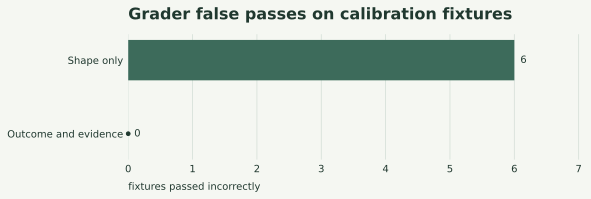

In [12]:
if COURSE_SMOKE:
    def infer_eval(case, context):
        required = case["evidence"]
        has_all = all(f"[{eid}]" in context for eid in required)
        return json.dumps({
            "decision": case["decision"],
            "value": case["value"] if has_all else "",
            "evidence": [eid for eid in required if f"[{eid}]" in context],
        })

    model_name = "smoke-fixture"
    model_load_ms = None
else:
    start = perf_counter_ns()
    eval_tokenizer, eval_model = load_text()
    sync()
    model_load_ms = (perf_counter_ns() - start) / 1e6

    def infer_eval(case, context):
        completion = generate(
            eval_tokenizer, eval_model, [answer_prompt(case, context)], max_new_tokens=MAX_NEW_TOKENS,
        )[0]
        sync()
        return completion

    model_name = MODEL_IDS["text"][0]

replay_started = perf_counter_ns()
discovery, discovery_spans, _ = eval_replay(discovery_cases, "candidate", infer_eval, model_name)
discovered_ids = [row["id"] for row in discovery if row["expected_inventory"] and not row["inventory_present"]]
assert discovered_ids, "The investigation fixture should expose the intended defect"
assert valid_trace_count(discovery, discovery_spans) == len(discovery)
incumbent, old_spans, incumbent_examples = eval_replay(gate_cases, "incumbent", infer_eval, model_name)
candidate, new_spans, candidate_examples = eval_replay(gate_cases, "candidate", infer_eval, model_name)
replay_ms = None if COURSE_SMOKE else (perf_counter_ns() - replay_started) / 1e6
assert digest(gate_cases) == gate_digest

gate = gate_evidence(candidate, incumbent)
gate["trace_coverage"] = {
    arm: {"valid": valid_trace_count(rows, trace_rows), "expected": len(rows)}
    for arm, rows, trace_rows in (("incumbent", incumbent, old_spans), ("candidate", candidate, new_spans))
}
assert all(counts["valid"] == counts["expected"] for counts in gate["trace_coverage"].values())
settings = {
    "split": "dev", "discovery_count": len(discovery_cases), "gate_count": len(gate_cases),
    "gate_family_count": len(gate_families), "model": MODEL_IDS["text"][0],
    "revision": MODEL_IDS["text"][1], "max_new_tokens": MAX_NEW_TOKENS, "temperature": 0,
    "serial_trials": len(discovery) + len(incumbent) + len(candidate),
}
timing = {"model_load_ms": model_load_ms, "discovery_and_gate_replay_ms": replay_ms}
print("Discovered defect IDs:", discovered_ids)
print("Paired gate:", json.dumps(gate, indent=2))
print("Timing and settings:", json.dumps({**timing, **settings}))
worked_examples = [*incumbent_examples, *candidate_examples]
print("F-211 worked comparison:", json.dumps([
    example for example in worked_examples if example["case_id"] == "F211-00"
], indent=2))
save("summary", {"mode": "fixture" if COURSE_SMOKE else "measured", "settings": settings,
                 "timing": timing, "grader_calibration": grading, "gate": gate})
save("records", [*incumbent, *candidate])
save("spans", [*old_spans, *new_spans])
save("manifest", {
    "discovery_ids": [case["id"] for case in discovery_cases],
    "discovery_families": sorted({case["family"] for case in discovery_cases}),
    "gate_ids": [case["id"] for case in gate_cases],
    "gate_families": sorted(gate_families),
    "gate_digest": gate_digest,
    "added_development_category": {
        "name": gate["category"], "case_ids": discovered_ids,
        "trace_ids": [row["trace_id"] for row in discovery if row["id"] in discovered_ids],
    },
    "calibration": calibration,
})
save("discovery_spans", discovery_spans)
save("worked_examples", worked_examples)
chart(
    "Grader false passes on calibration fixtures",
    ["Shape only", "Outcome and evidence"],
    [grading["shape"]["false_passes"], grading["strict"]["false_passes"]],
    "fixtures passed incorrectly",
)
if COURSE_SMOKE:
    assert gate["guard_failure_ids"] == ["F211-00", "F211-02", "F221-00", "F221-02"]
    by_case = {row["case_id"]: row for row in candidate_examples}
    assert by_case["F211-00"]["shape_pass"] == 1 and by_case["F211-00"]["verified"] == 0
    assert by_case["F211-01"]["verified"] == 1
    print("SMOKE OK")

### Read the result

Identify the model result, the heuristic disagreement and the deterministic
retrieval violation separately. Decide which one belongs in a release gate,
which failure needs more examples, and which aspects of the trace can travel
to a shared dashboard.

## Train a small classifier on labelled traces

The gold label comes from the synthetic event sequence. A scripted labeller
approximates a reviewer who sees some failures but routinely misses others.
Hold out equipment families for validation, calibration and test. Keep the
release split reserved. Compare checkpoint choices and report both on the
same balanced test set.

In [13]:
import json
import random

import torch
from torch import nn

random.seed(13)
torch.manual_seed(13)
CLASSES = (
    "wrong_tool_or_args", "tool_or_api_error", "premature_stop", "looping",
    "bad_plan", "hallucination", "skipped_verification", "ignored_instructions", "no_failure",
)
ENCODER_ID = "microsoft/deberta-v3-xsmall"
ENCODER_REVISION = "4b419818330868dff6a60ad3e6b1c730f8b8c0c6"
EVENTS = (
    ("manual lookup targeted the neighbouring asset", "the inventory query used a different family key"),
    ("inventory read returned a service error", "manual retrieval ended with a timeout"),
    ("ticket closed before either source was checked", "workflow handed off before the required lookup"),
    ("repeated the same query with identical arguments", "revisited the same step after receiving its result"),
    ("scheduled the evidence checks after posting the reply", "planned a source lookup after submitting the work"),
    ("cited a manual revision absent from the retrieved record", "reported a value absent from every read"),
    ("read the evidence and skipped the required provenance check", "submitted a sourced value before checking its revision"),
    ("carried on after the operator asked to stop", "continued after the desk received a handoff instruction"),
    ("checked the current manual and posted the cited value", "completed both authorised reads and verified the reply"),
)
BLIND = {"skipped_verification": "no_failure", "ignored_instructions": "no_failure"}
train_families = sorted({r["family"] for r in cases("train")})
dev_families = sorted({r["family"] for r in cases("dev")})
trace_splits = {
    "train": train_families, "validation": dev_families[:4],
    "calibration": dev_families[4:8], "test": dev_families[8:],
}
assert sum(map(len, trace_splits.values())) == len(set().union(*map(set, trace_splits.values())))


def trace_examples(families, variants):
    examples = []
    for family in families:
        for label, events in zip(CLASSES, EVENTS):
            for layout in variants:
                body = events[layout % len(events)]
                labeller = BLIND.get(label, label)
                confidence = 0.58 if label in BLIND else 0.91
                target = [(1 - confidence) / (len(CLASSES) - 1)] * len(CLASSES)
                target[CLASSES.index(labeller)] = confidence
                examples.append({
                    "family": family, "gold": label, "labeller": labeller, "target": target,
                    "trace": f"Facilities desk {family}. {body}." if layout < 2 else f"Desk event: {body}. Equipment family {family}.",
                })
    return examples


trace_data = {
    key: trace_examples(families[:1] if COURSE_SMOKE else families, (0, 1) if key == "train" else (2, 3))
    for key, families in trace_splits.items()
}


def label_audit(rows, predictions):
    return {
        label: {
            "support": sum(row["gold"] == label for row in rows),
            "correct": sum(row["gold"] == label and got == label for row, got in zip(rows, predictions)),
        }
        for label in CLASSES
    }


teacher_audit = label_audit(trace_data["validation"], [r["labeller"] for r in trace_data["validation"]])
assert all(teacher_audit[label]["correct"] == 0 for label in BLIND)

### Compare checkpoint selection rules

Train on the soft distributions from the labeller. Evaluate both the
agreement-selected checkpoint and the gold-selected checkpoint. The latter
is the one sent to calibration. The local fixture exercises the same loss,
optimiser and score paths without fetching pretrained weights.

In [14]:
device = torch.device("cpu" if COURSE_SMOKE else "cuda")
if not COURSE_SMOKE:
    assert "T4" in torch.cuda.get_device_name(device)
    from transformers import AutoModel, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(ENCODER_ID, revision=ENCODER_REVISION, use_fast=False)
    pretrained = AutoModel.from_pretrained(ENCODER_ID, revision=ENCODER_REVISION)


class TraceClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Embedding(4096, 24) if COURSE_SMOKE else pretrained
        width = 24 if COURSE_SMOKE else self.encoder.config.hidden_size
        self.head = nn.Sequential(nn.Linear(width, 32), nn.GELU(), nn.Linear(32, len(CLASSES)))

    def forward(self, ids, mask):
        hidden = self.encoder(ids) if COURSE_SMOKE else self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        features = (hidden * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp_min(1)
        return self.head(features)


def encode(rows):
    texts = [r["trace"] for r in rows]
    if COURSE_SMOKE:
        tokens = [[int(identifier(word, 2), 16) % 4095 + 1 for word in text.split()] for text in texts]
        width = max(map(len, tokens))
        ids = torch.tensor([row + [0] * (width - len(row)) for row in tokens])
        return ids.to(device), ids.ne(0).to(device)
    batch = tokenizer(texts, padding=True, truncation=True, max_length=96, return_tensors="pt")
    return batch.input_ids.to(device), batch.attention_mask.to(device)


def labels(rows, key):
    return torch.tensor([CLASSES.index(r[key]) for r in rows])


classifier = TraceClassifier().to(device)
encoder_lr, head_lr = 2e-5, 4e-4
optim = torch.optim.AdamW([
    {"params": classifier.encoder.parameters(), "lr": encoder_lr},
    {"params": classifier.head.parameters(), "lr": head_lr},
])
amp = not COURSE_SMOKE
scaler = torch.amp.GradScaler("cuda", enabled=amp)
batch_size, epochs = 24, 2 if COURSE_SMOKE else 6


@torch.no_grad()
def trace_logits(rows):
    classifier.eval()
    results = []
    for start in range(0, len(rows), batch_size):
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            results.append(classifier(*encode(rows[start:start + batch_size])).float().cpu())
    return torch.cat(results)


best, history = {}, []
train_rows = trace_data["train"]
validation_rows = trace_data["validation"]
for epoch in range(epochs + 1):
    classifier.train()
    epoch_losses = []
    if epoch:
        random.shuffle(train_rows)
        for start in range(0, len(train_rows), batch_size):
            batch = train_rows[start:start + batch_size]
            target = torch.tensor([r["target"] for r in batch], device=device, dtype=torch.float32)
            optim.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                logits = classifier(*encode(batch))
            loss = -(target * torch.log_softmax(logits.float(), -1)).sum(-1).mean()
            scaler.scale(loss).backward()
            scaler.step(optim)
            scaler.update()
            epoch_losses.append(loss.item())
    hits = trace_logits(validation_rows).argmax(dim=-1)
    scores = {key: hits.eq(labels(validation_rows, key)).float().mean().item() for key in ("gold", "labeller")}
    history.append({"epoch": epoch, "validation": scores, "mean_training_loss": mean(epoch_losses) if epoch_losses else None})
    for key, score in scores.items():
        if key not in best or score > best[key]["score"]:
            best[key] = {
                "score": score, "epoch": epoch,
                "weights": {k: v.detach().cpu().clone() for k, v in classifier.state_dict().items()},
            }

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/241M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/241M [00:00<?, ?B/s]

In [15]:
def expected_calibration_error(probabilities, gold, bins=10):
    confidence, predicted = probabilities.max(dim=1)
    correct = predicted.eq(gold).float()
    assignment = torch.clamp((confidence * bins).long(), max=bins - 1)
    contributions = []
    for b in range(bins):
        mask = assignment.eq(b)
        if mask.any():
            contributions.append(mask.float().mean() * (confidence[mask].mean() - correct[mask].mean()).abs())
    return torch.stack(contributions).sum().item()


test_rows = trace_data["test"]
test_gold = labels(test_rows, "gold")
checkpoint_results = {}
for key in ("labeller", "gold"):
    classifier.load_state_dict(best[key]["weights"])
    test_scores = trace_logits(test_rows)
    predicted = test_scores.argmax(dim=-1)
    checkpoint_results[key] = {
        "epoch": best[key]["epoch"],
        "validation_agreement": best[key]["score"],
        "test_gold_accuracy": predicted.eq(test_gold).float().mean().item(),
        "test_labeller_agreement": predicted.eq(labels(test_rows, "labeller")).float().mean().item(),
        "per_class_gold": label_audit(test_rows, [CLASSES[i] for i in predicted.tolist()]),
    }

# Class absence is a test-set ablation. Fit the temperature on calibration only.
absent = CLASSES.index("skipped_verification")
included = test_gold.ne(absent)
per_class = checkpoint_results["gold"]["per_class_gold"]
assert all(v["support"] > 0 for v in per_class.values())
masked_support = {
    label: int(test_gold[included].eq(i).sum().item()) for i, label in enumerate(CLASSES)
}
assert [label for label, support in masked_support.items() if support == 0] == ["skipped_verification"]
coverage = {
    "balanced": checkpoint_results["gold"]["test_gold_accuracy"],
    "without_skipped_verification": predicted[included].eq(test_gold[included]).float().mean().item(),
    "remaining_support": masked_support,
}
calibration_rows = trace_data["calibration"]
calibration_logits = trace_logits(calibration_rows)
calibration_gold = labels(calibration_rows, "gold")
log_temperature = torch.zeros((), requires_grad=True)
temp_optim = torch.optim.LBFGS([log_temperature], max_iter=25, line_search_fn="strong_wolfe")


def temperature_objective():
    temp_optim.zero_grad()
    loss = nn.functional.cross_entropy(calibration_logits / log_temperature.clamp(-3, 3).exp(), calibration_gold)
    loss.backward()
    return loss


temp_optim.step(temperature_objective)
temperature = log_temperature.detach().clamp(-3, 3).exp()
plain = test_scores.softmax(-1)
scaled = (test_scores / temperature).softmax(-1)
assert torch.equal(plain.argmax(-1), scaled.argmax(-1))
calibration_summary = {
    "temperature": temperature.item(), "ece_before": expected_calibration_error(plain, test_gold),
    "ece_after": expected_calibration_error(scaled, test_gold), "bins": 10,
    "nll_before": nn.functional.cross_entropy(test_scores, test_gold).item(),
    "nll_after": nn.functional.cross_entropy(test_scores / temperature, test_gold).item(),
}
save("trace_classifier", {
    "mode": "fixture" if COURSE_SMOKE else "measured", "classes": CLASSES, "splits": trace_splits,
    "labeller_per_class": teacher_audit, "history": history, "checkpoints": checkpoint_results,
    "coverage": coverage, "calibration": calibration_summary,
    "settings": {
        "encoder": ENCODER_ID, "revision": ENCODER_REVISION, "head_hidden": 32,
        "precision": "float32" if COURSE_SMOKE else "fp16 mixed precision",
        "encoder_lr": encoder_lr, "head_lr": head_lr, "epochs": epochs, "batch_size": batch_size,
    },
})
save("trace_classifier_records", {
    "validation": validation_rows,
    "test": [
        {**row, "predicted": CLASSES[int(predicted[i])], "probabilities": plain[i].tolist(),
         "calibrated_probabilities": scaled[i].tolist()}
        for i, row in enumerate(test_rows)
    ],
})
print("Labeller audit against gold:", json.dumps(teacher_audit))
print("Checkpoint choices:", json.dumps(checkpoint_results))
print("Class coverage ablation:", json.dumps(coverage))
print("Held-out test calibration:", json.dumps(calibration_summary))
if COURSE_SMOKE:
    assert all(0 <= calibration_summary[k] <= 1 for k in ("ece_before", "ece_after"))
    print("SMOKE OK")

Evidence saved to evidence/trace_classifier.json
Evidence saved to evidence/trace_classifier_records.json
Labeller audit against gold: {"wrong_tool_or_args": {"support": 8, "correct": 8}, "tool_or_api_error": {"support": 8, "correct": 8}, "premature_stop": {"support": 8, "correct": 8}, "looping": {"support": 8, "correct": 8}, "bad_plan": {"support": 8, "correct": 8}, "hallucination": {"support": 8, "correct": 8}, "skipped_verification": {"support": 8, "correct": 0}, "ignored_instructions": {"support": 8, "correct": 0}, "no_failure": {"support": 8, "correct": 8}}
Checkpoint choices: {"labeller": {"epoch": 3, "validation_agreement": 1.0, "test_gold_accuracy": 0.7777777910232544, "test_labeller_agreement": 1.0, "per_class_gold": {"wrong_tool_or_args": {"support": 8, "correct": 8}, "tool_or_api_error": {"support": 8, "correct": 8}, "premature_stop": {"support": 8, "correct": 8}, "looping": {"support": 8, "correct": 8}, "bad_plan": {"support": 8, "correct": 8}, "hallucination": {"support": 

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [OpenTelemetry GenAI Semantic Conventions](https://opentelemetry.io/docs/specs/semconv/gen-ai/)
- [tau-bench: A Benchmark for Tool-Agent-User Interaction in Real-World Domains](https://arxiv.org/abs/2406.12045)